In [24]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "metadata" / "arxiv_metadata.csv"

## Load

In [25]:
df_raw = pd.read_csv(
    DATA,
    dtype=str,  # keeps IDs like 0704.0001 intact
    keep_default_na=False,
)
for c in ["v1_date", "last_date", "datestamp"]:
    df_raw[c] = pd.to_datetime(df_raw[c], errors="coerce")
for c in ["n_versions", "v1_size_kb", "last_size_kb"]:
    df_raw[c] = pd.to_numeric(df_raw[c], errors="coerce")
df_raw["v1_year"] = df_raw["v1_date"].dt.year

# November 2026 was not harvested: drop it so 2026 is not half-filled
df_raw = df_raw[df_raw["v1_date"] < "2026-11-01"]
len(df_raw)

3216224

## Overview

In [42]:
df_raw.head(100)

,id,title,primary_category,categories,archive,group,v1_date,v1_year,n_versions,last_date,v1_size_kb,last_size_kb,v1_source_type,license,doi,journal_ref,datestamp
0,physics/9403001,Desperately Seeking Superstrings,physics.pop-ph,physics.pop-ph hep-th,physics,physics,1986-04-25,1986,1,1986-04-25,3,3,,,10.1063/1.2814991,Phys.Today 86N5 (1986) 7-9,2015-06-26
1,hep-th/9108028,Applied Conformal Field Theory,hep-th,hep-th,hep-th,physics,1988-11-11,1988,1,1988-11-11,260,260,,,,"Fields, Strings and Critical Phenomena, (Les H...",2008-02-06
2,math/9201239,A note on canonical functions,math.LO,math.LO,math,math,1989-04-15,1989,1,1989-04-15,4,4,,,,"Israel J. Math. 68 (1989), 376--380",2009-09-25
3,math/9201203,Convex bodies with few faces,math.MG,math.MG math.FA,math,math,1989-10-26,1989,1,1989-10-26,6,6,,,,,2016-09-06
4,math/9201204,Shadows of convex bodies,math.MG,math.MG math.FA,math,math,1989-10-26,1989,1,1989-10-26,8,8,,,,,2016-09-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,hep-th/9108026,Superstring in Two Dimensional Black Hole,hep-th,hep-th,hep-th,physics,1991-08-29,1991,2,1991-09-02,0,6,,,10.1016/0370-2693(92)90301-J,"Phys.Lett.B274:41-46,1992",2011-04-20
96,hep-th/9108027,Factorization and Topological States in $c=1$ ...,hep-th,hep-th,hep-th,physics,1991-08-30,1991,2,1991-09-02,0,11,,,10.1016/0370-2693(92)90539-G,Phys.Lett. B276 (1992) 41-48,2009-10-22
97,hep-th/9109001,Fractional Superstrings with Space-Time Critic...,hep-th,hep-th,hep-th,physics,1991-09-02,1991,2,1991-09-07,0,9,,,10.1103/PhysRevLett.67.3339,Phys.Rev.Lett. 67 (1991) 3339-3342,2009-10-22
98,hep-th/9109002,Ashtekar's Approach to Quantum Gravity,hep-th,hep-th,hep-th,physics,1991-09-03,1991,1,1991-09-03,14,14,,,,"In Strings and Symmetries 1991, World Scientif...",2005-09-17


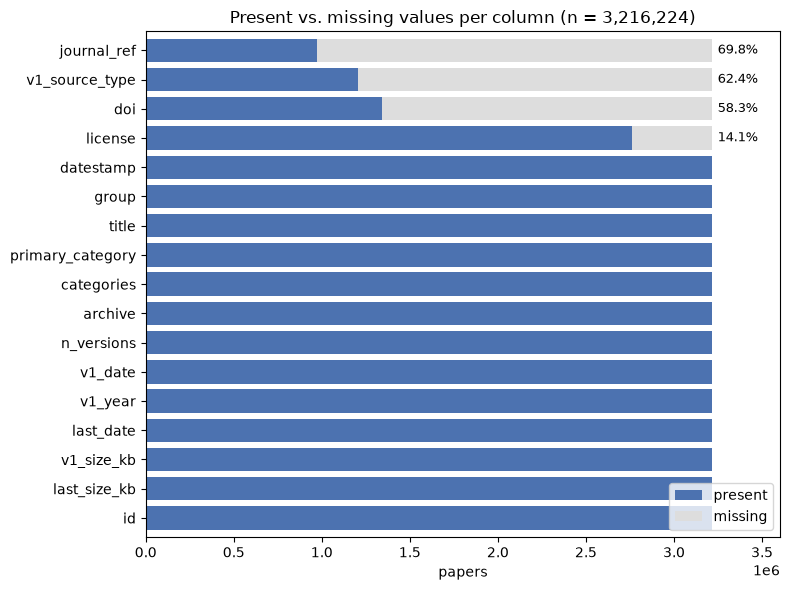

,present,missing,missing_share
id,3216224,0,0.0000
last_size_kb,3216224,0,0.0000
v1_size_kb,3216224,0,0.0000
last_date,3216224,0,0.0000
v1_year,3216224,0,0.0000
v1_date,3216224,0,0.0000
n_versions,3216224,0,0.0000
archive,3216224,0,0.0000
categories,3216224,0,0.0000
primary_category,3216224,0,0.0000


In [27]:
# Missing = empty text (""), unparseable date (NaT) or number (NaN)
missing = (df_raw == "") | df_raw.isna()
counts = pd.DataFrame({
    "present": (~missing).sum(),
    "missing": missing.sum(),
}).sort_values("missing")

ax = counts.plot.barh(stacked=True, figsize=(8, 6), color=["#4C72B0", "#DDDDDD"], width=0.8)
ax.set_xlabel("papers")
ax.set_title(f"Present vs. missing values per column (n = {len(df_raw):,})")
for i, (col, row) in enumerate(counts.iterrows()):
    share = row["missing"] / len(df_raw)
    if share > 0:
        ax.text(len(df_raw) * 1.01, i, f"{share:.1%}", va="center", fontsize=9)
ax.set_xlim(0, len(df_raw) * 1.12)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

counts.assign(missing_share=(counts["missing"] / len(df_raw)).round(4))

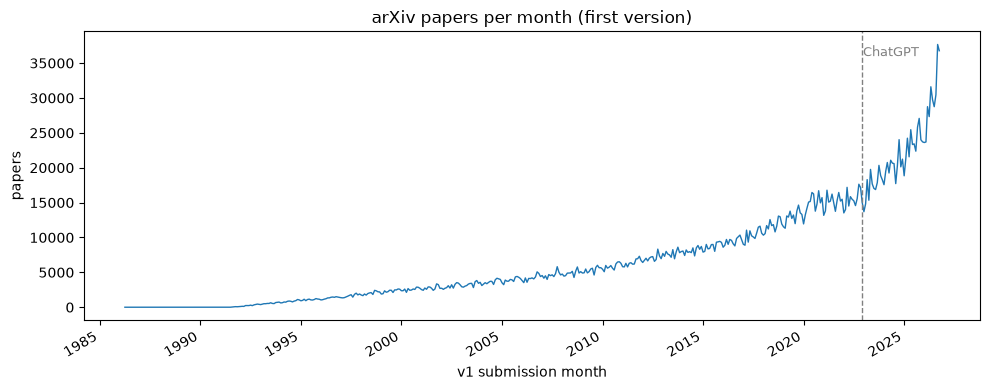

In [28]:
per_month = (
    df_raw["v1_date"].dt.to_period("M")
    .value_counts()
    .sort_index()
)
per_month.index = per_month.index.to_timestamp()

ax = per_month.plot(figsize=(10, 4), linewidth=1)
ax.axvline(pd.Timestamp("2022-11-30"), color="grey", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2022-12-15"), ax.get_ylim()[1] * 0.95, "ChatGPT", color="grey", fontsize=9, va="top")
ax.set_xlabel("v1 submission month")
ax.set_ylabel("papers")
ax.set_title("arXiv papers per month (first version)")
plt.tight_layout()
plt.show()

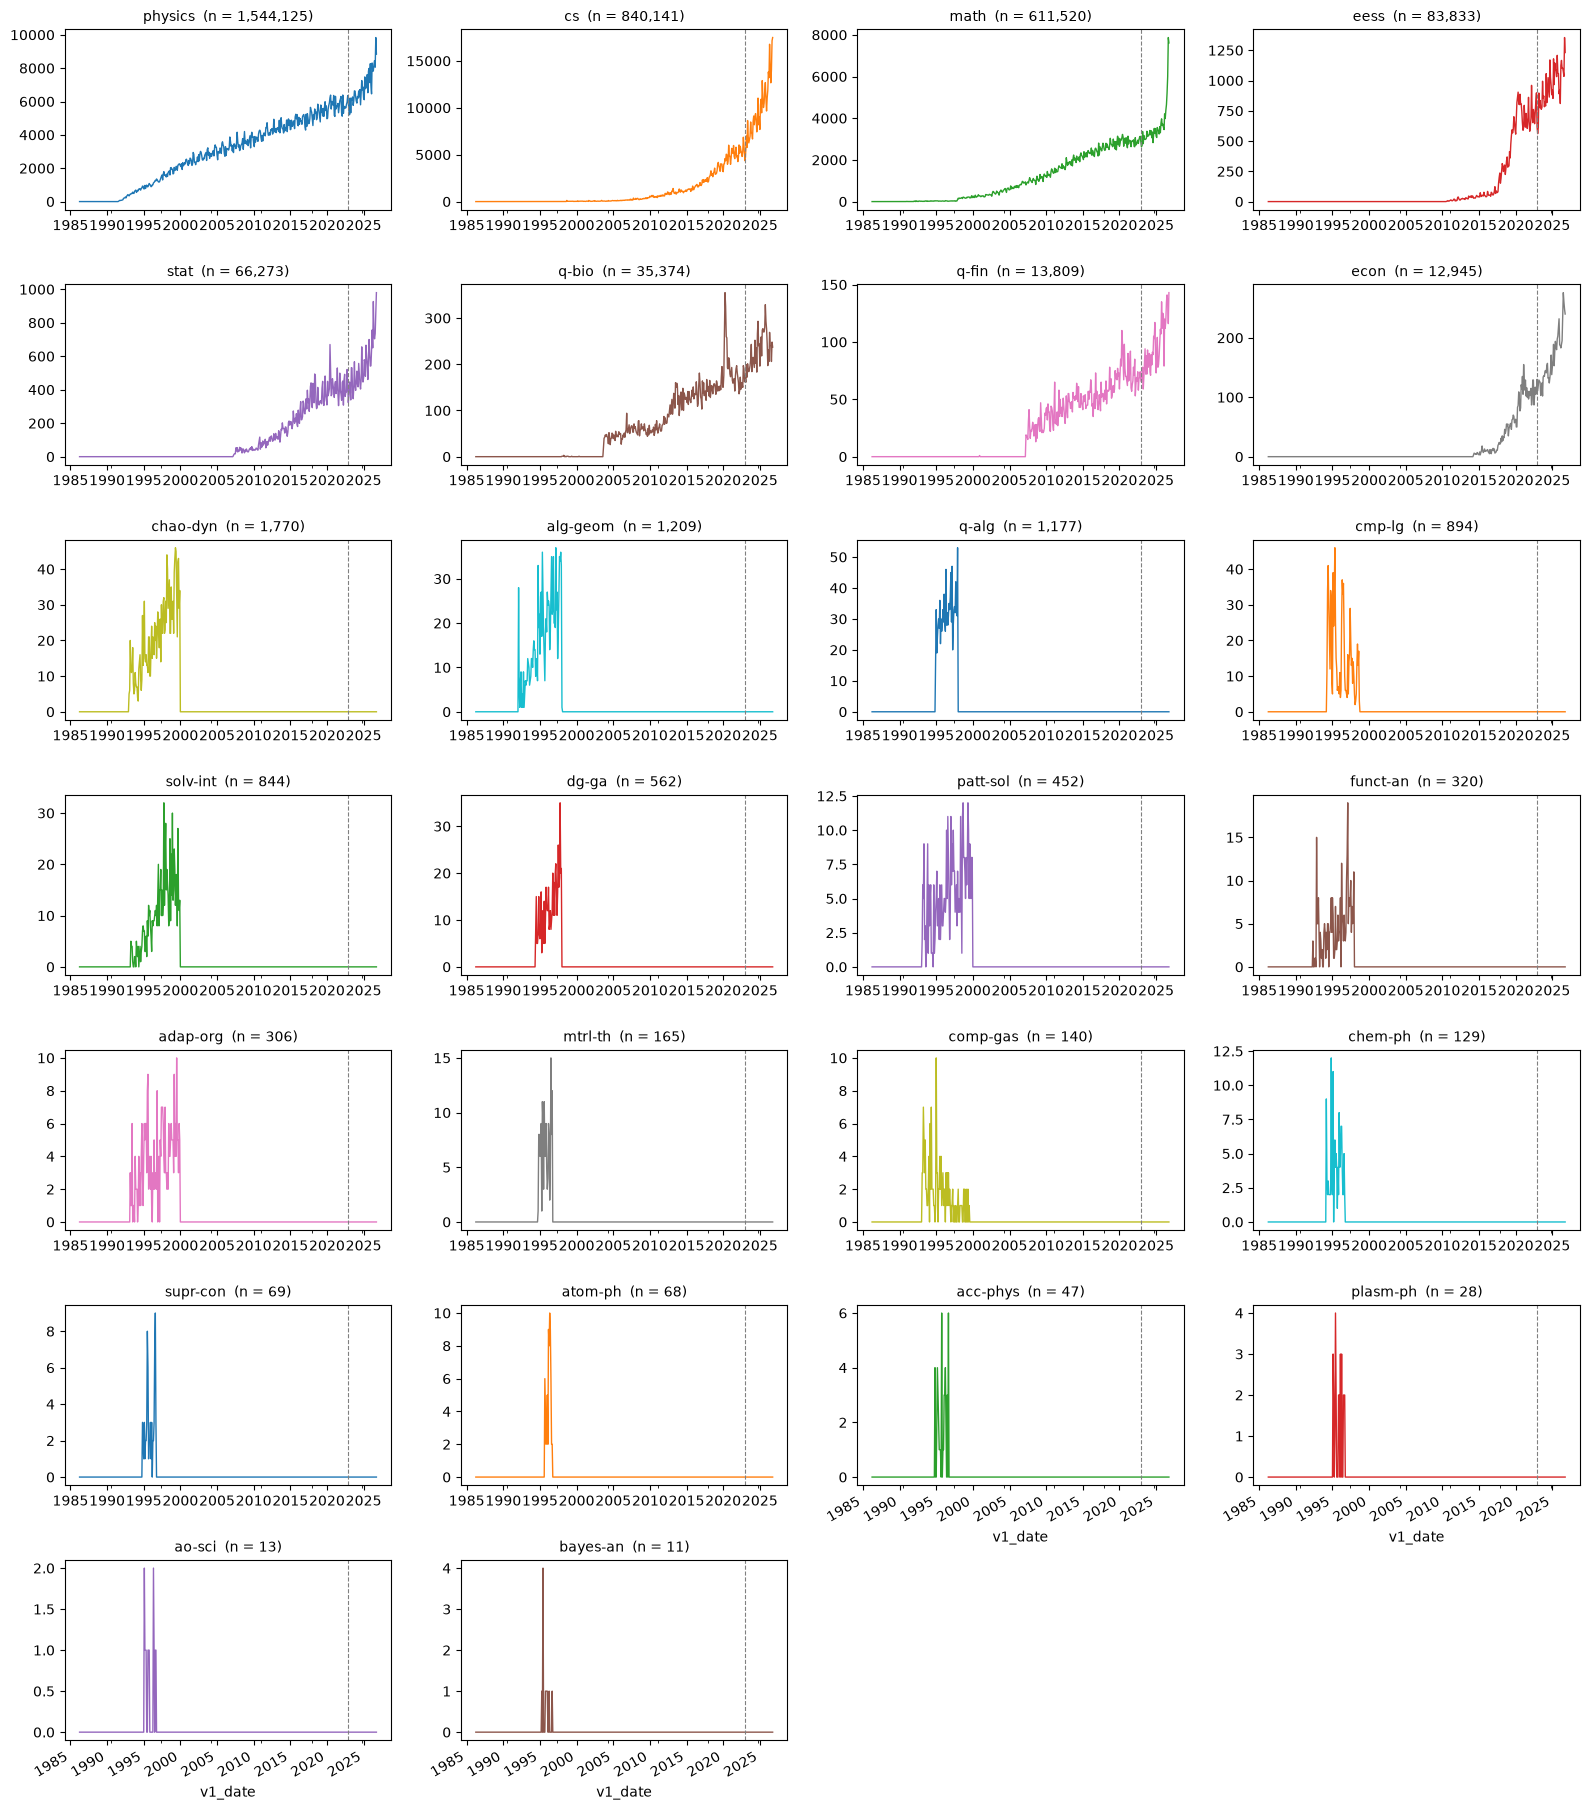

In [29]:
per_month = (
    df_raw.groupby([df_raw["v1_date"].dt.to_period("M"), "group"])
    .size()
    .unstack(fill_value=0)
)
per_month.index = per_month.index.to_timestamp()
per_month = per_month[per_month.sum().sort_values(ascending=False).index]  # largest first

n = per_month.shape[1]
cols = 4
rows = -(-n // cols)  # round up

axes = per_month.plot(
    subplots=True,
    layout=(rows, cols),
    figsize=(16, 2.6 * rows),
    sharex=True,
    sharey=False,   # own y-axis per field
    legend=False,
    linewidth=1,
)
for ax, name in zip(axes.flat, per_month.columns):
    ax.set_title(f"{name}  (n = {per_month[name].sum():,})", fontsize=10)
    ax.axvline(pd.Timestamp("2022-11-30"), color="grey", linestyle="--", linewidth=0.8)
    ax.tick_params(axis="x", labelbottom=True)   # show tick labels on every plot
    for label in ax.get_xticklabels():           # pandas hides them one by one
        label.set_visible(True)

for ax in axes.flat[n:]:   # hide empty grid cells
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [30]:
df_raw.head()

,id,title,primary_category,categories,archive,group,v1_date,v1_year,n_versions,last_date,v1_size_kb,last_size_kb,v1_source_type,license,doi,journal_ref,datestamp
0,physics/9403001,Desperately Seeking Superstrings,physics.pop-ph,physics.pop-ph hep-th,physics,physics,1986-04-25,1986,1,1986-04-25,3,3,,,10.1063/1.2814991,Phys.Today 86N5 (1986) 7-9,2015-06-26
1,hep-th/9108028,Applied Conformal Field Theory,hep-th,hep-th,hep-th,physics,1988-11-11,1988,1,1988-11-11,260,260,,,,"Fields, Strings and Critical Phenomena, (Les H...",2008-02-06
2,math/9201239,A note on canonical functions,math.LO,math.LO,math,math,1989-04-15,1989,1,1989-04-15,4,4,,,,"Israel J. Math. 68 (1989), 376--380",2009-09-25
3,math/9201203,Convex bodies with few faces,math.MG,math.MG math.FA,math,math,1989-10-26,1989,1,1989-10-26,6,6,,,,,2016-09-06
4,math/9201204,Shadows of convex bodies,math.MG,math.MG math.FA,math,math,1989-10-26,1989,1,1989-10-26,8,8,,,,,2016-09-06


/var/folders/pr/gkmk7_g15yn0_83qz1954zpw0000gn/T/ipykernel_29291/1601791940.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_raw[df_raw["group"].isin(kept_groups)][df_raw["v1_date"].dt.to_period("M") >= "2005-09"]


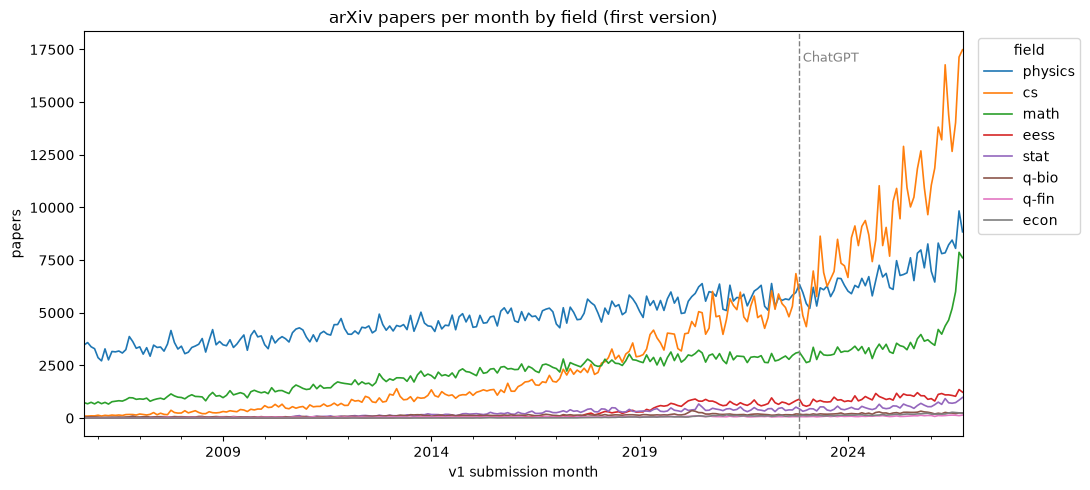

In [35]:
kept_groups =   df_raw[df_raw["v1_year"] >= 2005]["group"].unique()
per_month = (
    df_raw[df_raw["group"].isin(kept_groups)][df_raw["v1_date"].dt.to_period("M") >= "2005-09"]
    .groupby([df_raw["v1_date"].dt.to_period("M"), "group"])
    .size()
    .unstack(fill_value=0)
)
per_month.index = per_month.index.to_timestamp()
per_month = per_month[per_month.sum().sort_values(ascending=False).index]  # legend from largest to smallest

ax = per_month.plot(figsize=(11, 5), linewidth=1.2)
ax.axvline(pd.Timestamp("2022-11-30"), color="grey", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2022-12-15"), ax.get_ylim()[1] * 0.95, "ChatGPT", color="grey", fontsize=9, va="top")
ax.set_xlabel("v1 submission month")
ax.set_ylabel("papers")
ax.set_title("arXiv papers per month by field (first version)")
ax.legend(title="field", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

/var/folders/pr/gkmk7_g15yn0_83qz1954zpw0000gn/T/ipykernel_29291/2266642122.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_raw[df_raw["group"].isin(["econ", "q-fin", "q-bio","stat", "eess"])][df_raw["v1_date"].dt.to_period("M") >= "2005-09"]


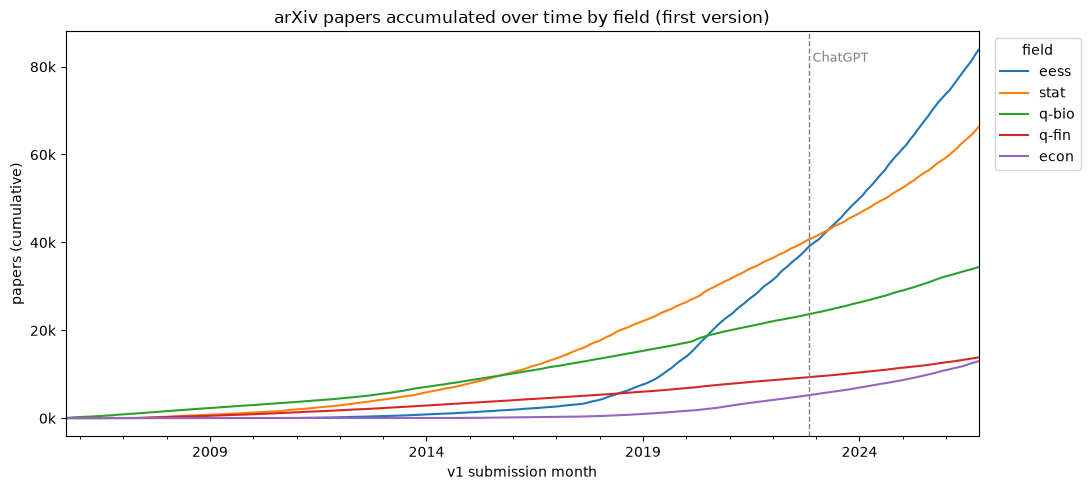

In [39]:
per_month = (
    df_raw[df_raw["group"].isin(["econ", "q-fin", "q-bio","stat", "eess"])][df_raw["v1_date"].dt.to_period("M") >= "2005-09"]
    .groupby([df_raw["v1_date"].dt.to_period("M"), "group"])
    .size()
    .unstack(fill_value=0)
)
per_month.index = per_month.index.to_timestamp()
cumulative = per_month.cumsum()
cumulative = cumulative[cumulative.iloc[-1].sort_values(ascending=False).index]  # legend from largest to smallest

ax = cumulative.plot(figsize=(11, 5), linewidth=1.5)
ax.axvline(pd.Timestamp("2022-11-30"), color="grey", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2022-12-15"), ax.get_ylim()[1] * 0.95, "ChatGPT", color="grey", fontsize=9, va="top")
ax.set_xlabel("v1 submission month")
ax.set_ylabel("papers (cumulative)")
ax.set_title("arXiv papers accumulated over time by field (first version)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M" if x >= 1e6 else f"{x / 1e3:.0f}k"))
ax.legend(title="field", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()


/var/folders/pr/gkmk7_g15yn0_83qz1954zpw0000gn/T/ipykernel_29291/3603213994.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_raw[df_raw["group"].isin(["econ", "q-fin", "q-bio","stat", "eess"])][df_raw["v1_date"].dt.to_period("M") >= "2005-09"]


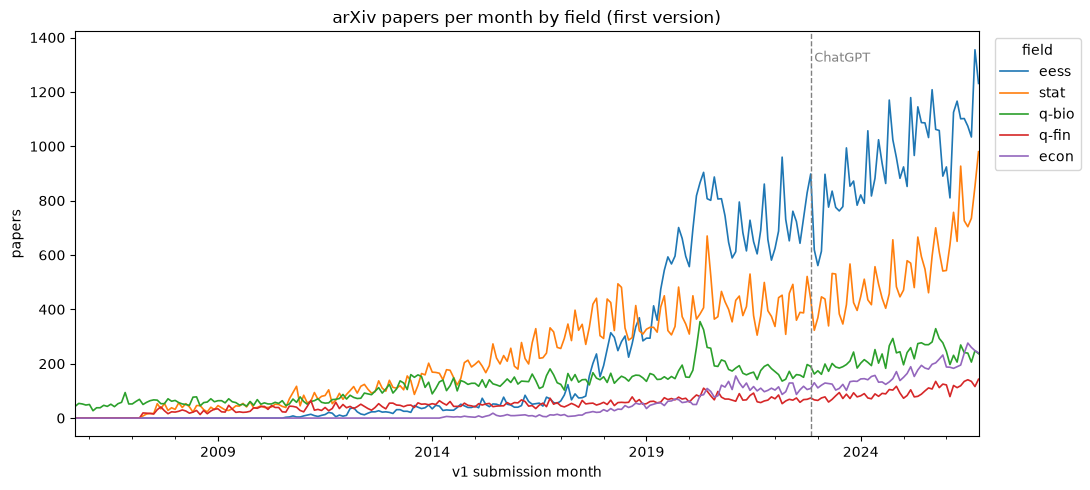

In [40]:
per_month = (
    df_raw[df_raw["group"].isin(["econ", "q-fin", "q-bio","stat", "eess"])][df_raw["v1_date"].dt.to_period("M") >= "2005-09"]
    .groupby([df_raw["v1_date"].dt.to_period("M"), "group"])
    .size()
    .unstack(fill_value=0)
)
per_month.index = per_month.index.to_timestamp()
per_month = per_month[per_month.sum().sort_values(ascending=False).index]  # legend from largest to smallest

ax = per_month.plot(figsize=(11, 5), linewidth=1.2)
ax.axvline(pd.Timestamp("2022-11-30"), color="grey", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2022-12-15"), ax.get_ylim()[1] * 0.95, "ChatGPT", color="grey", fontsize=9, va="top")
ax.set_xlabel("v1 submission month")
ax.set_ylabel("papers")
ax.set_title("arXiv papers per month by field (first version)")
ax.legend(title="field", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

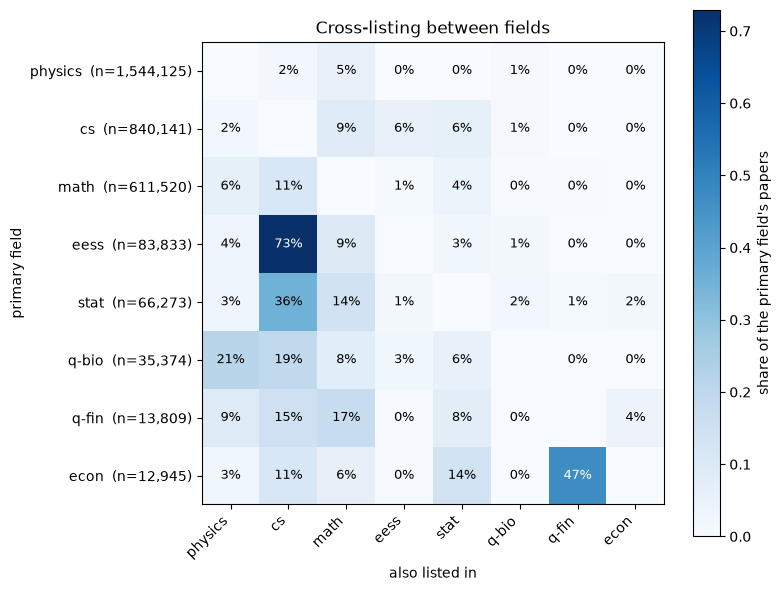

In [41]:
PHYSICS = {"astro-ph", "cond-mat", "gr-qc", "hep-ex", "hep-lat", "hep-ph", "hep-th", "math-ph",
           "nlin", "nucl-ex", "nucl-th", "physics", "quant-ph"}
to_group = lambda cat: "physics" if cat.split(".")[0] in PHYSICS else cat.split(".")[0]

# one row per (paper, field it is cross-listed in), own field excluded
cross = (
    df[["id", "group", "categories"]]
    .assign(cross=lambda d: d["categories"].str.split().str[1:])
    .explode("cross")
    .dropna(subset=["cross"])
    .assign(cross=lambda d: d["cross"].map(to_group))
    .query("cross != group")
    .drop_duplicates(["id", "cross"])
)
order = df["group"].value_counts().index[:8]          # the 8 main fields, largest first
n_papers = df["group"].value_counts()
share = (
    pd.crosstab(cross["group"], cross["cross"])
    .reindex(index=order, columns=order, fill_value=0)
    .div(n_papers[order], axis=0)
)

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(share, cmap="Blues", vmin=0, vmax=share.values.max())
ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
ax.set_yticks(range(len(order)), [f"{g}  (n={n_papers[g]:,})" for g in order])
ax.set_xlabel("also listed in")
ax.set_ylabel("primary field")
for i in range(len(order)):
    for j in range(len(order)):
        v = share.iat[i, j]
        if i != j:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if v > share.values.max() * 0.6 else "black")
fig.colorbar(im, ax=ax, label="share of the primary field's papers")
ax.set_title("Cross-listing between fields")
plt.tight_layout()
plt.show()

## Topic selection

## Dataset selection


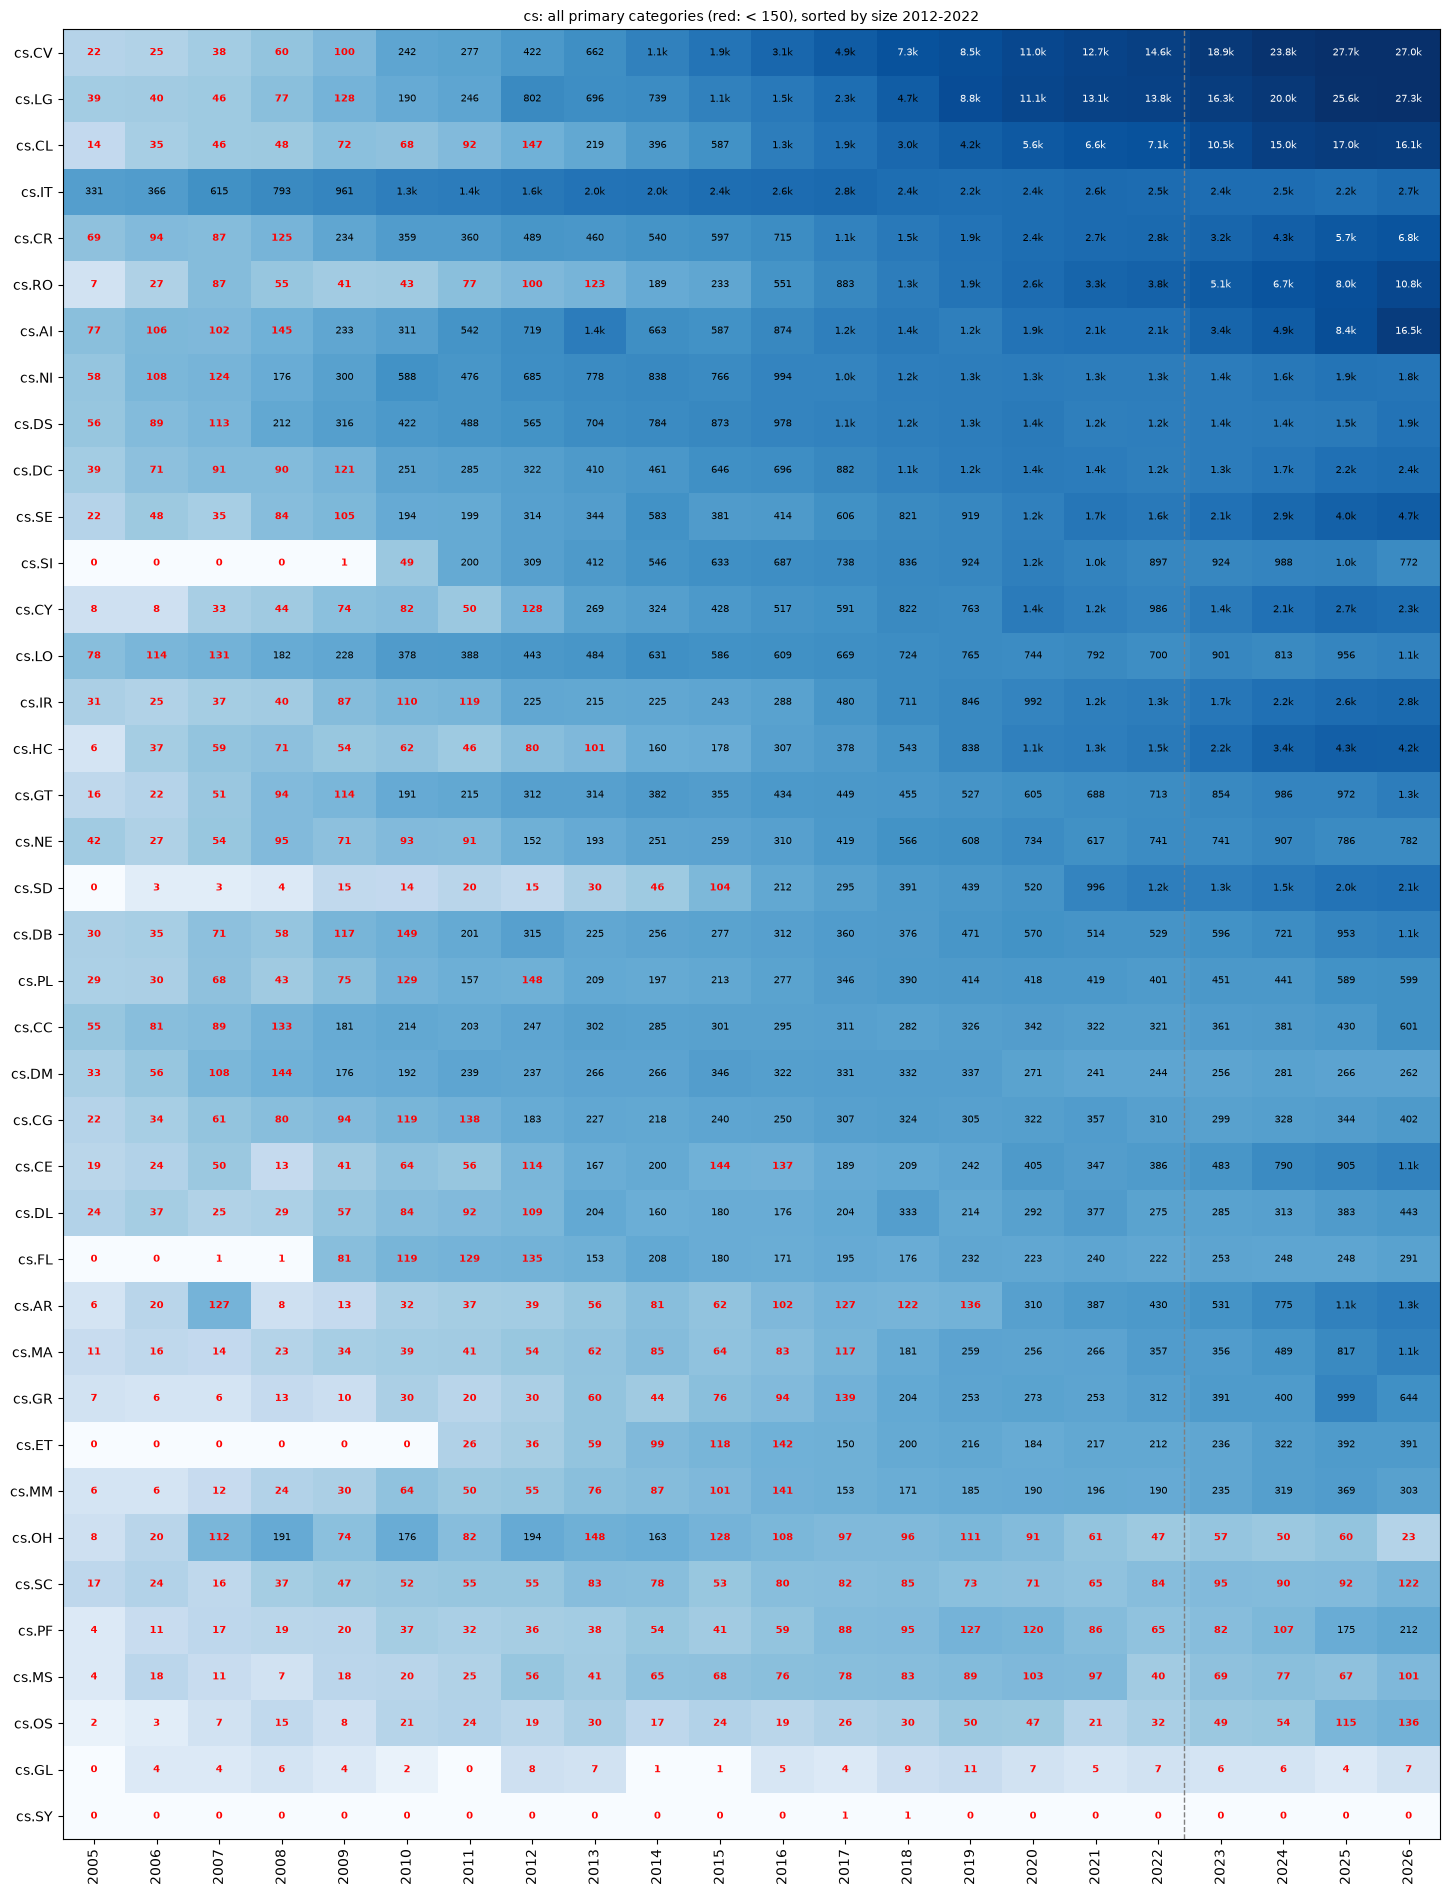

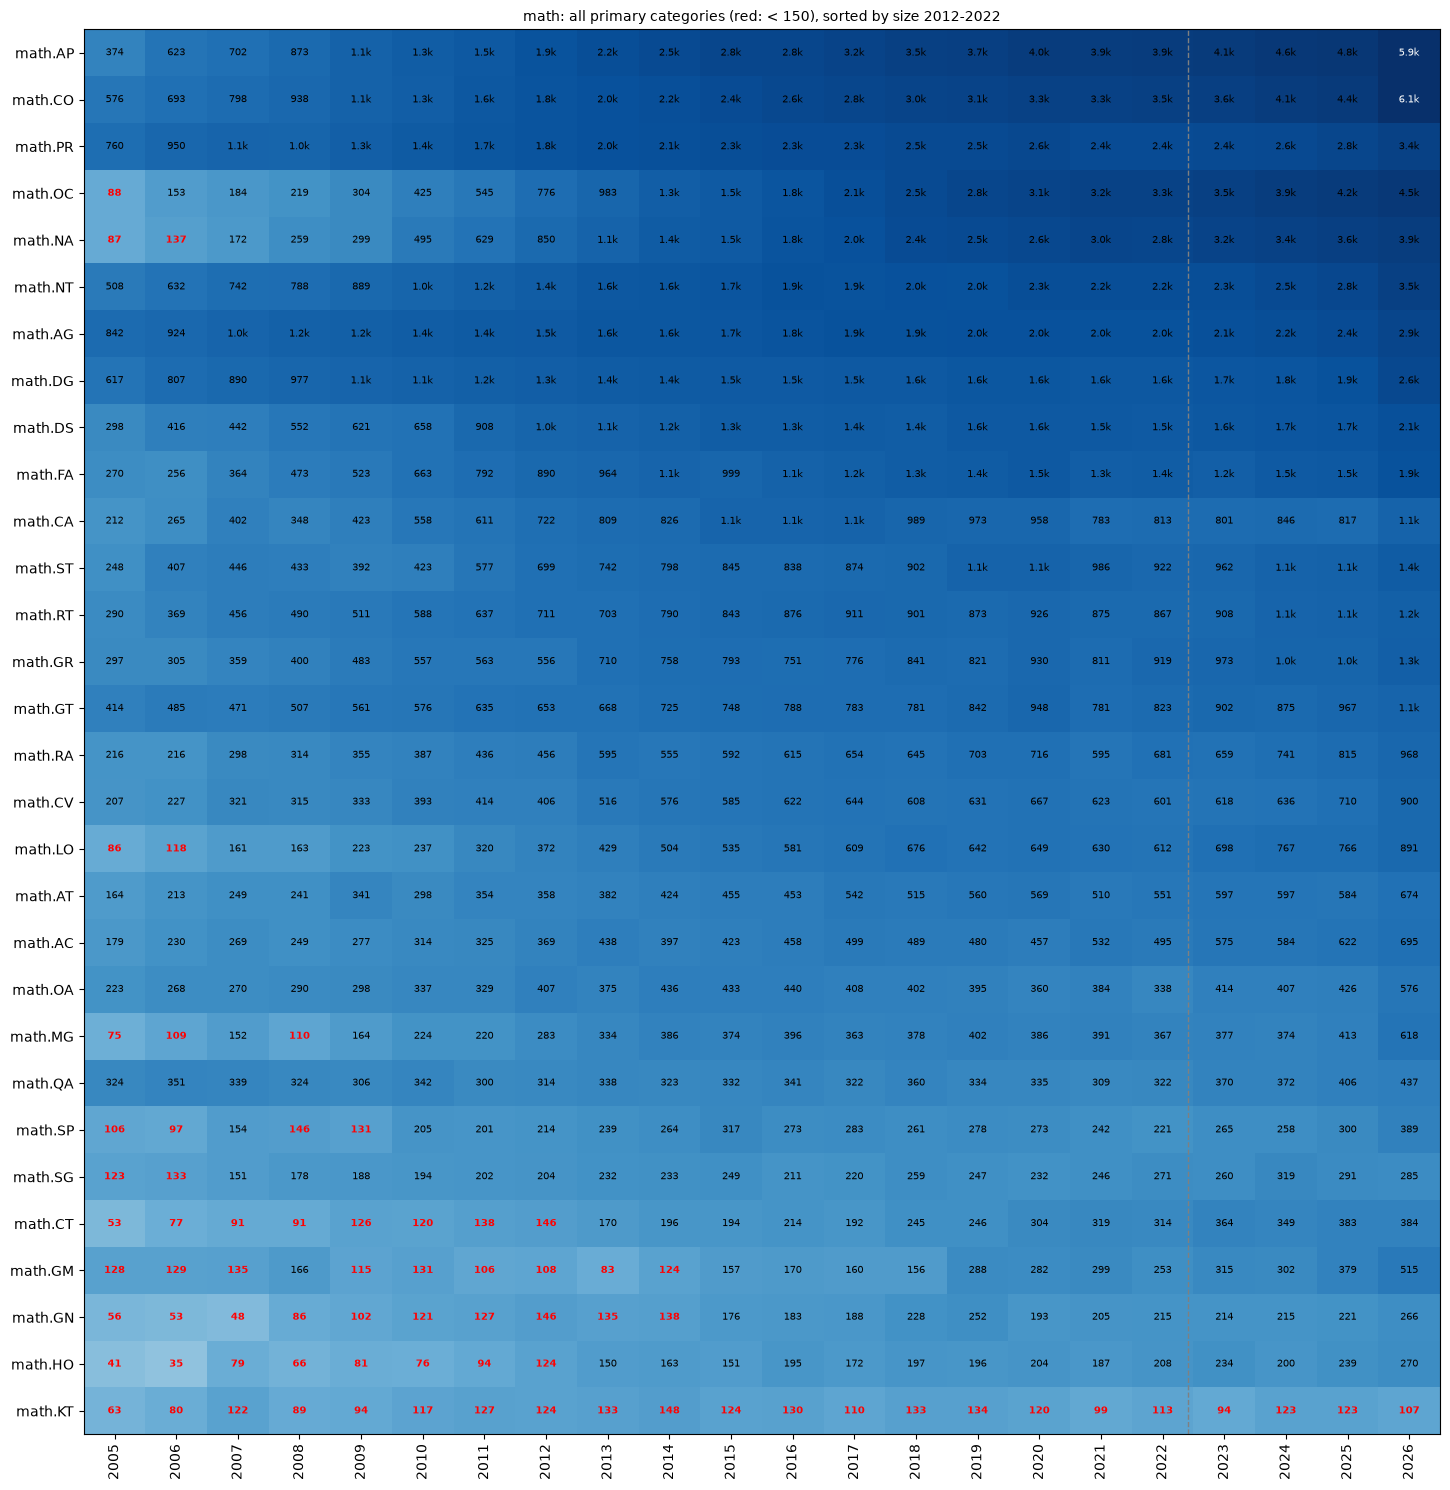

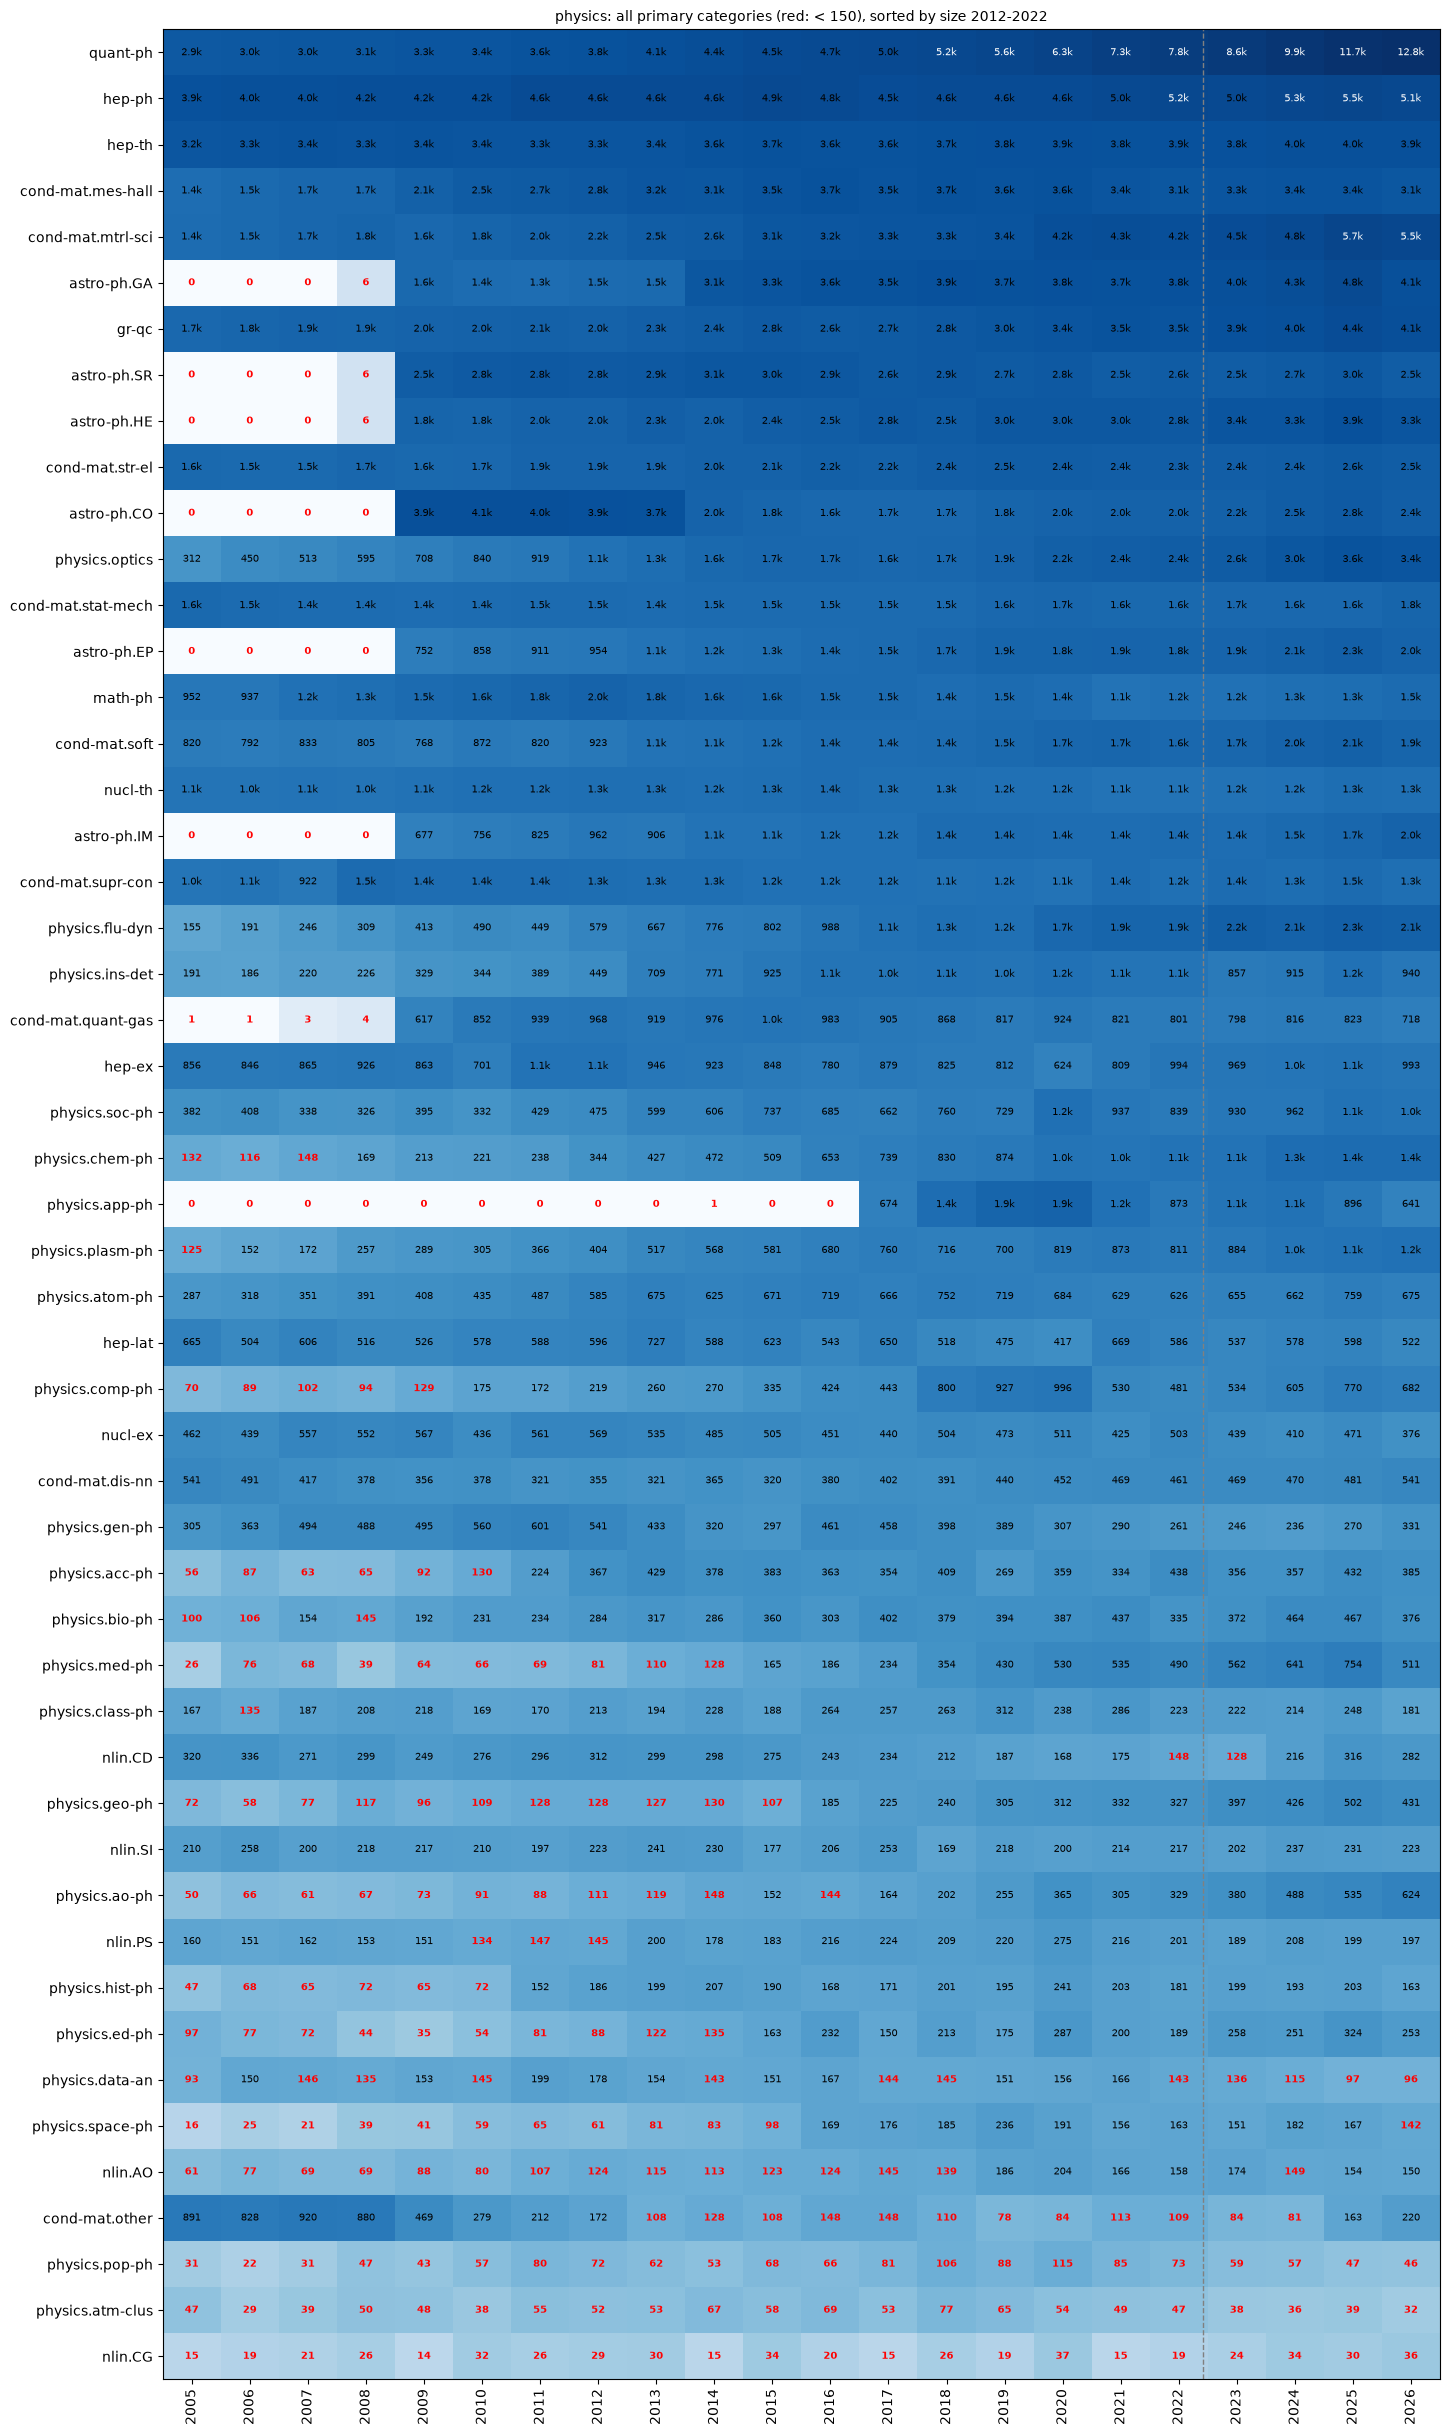

In [46]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LogNorm


def plot_strata(data, strata, start=2005, end=2026, n_min=150, title=None):
    """Papers per stratum and year. A stratum is a group ("cs"),
    an archive ("hep-th") or a primary category ("cs.CL").
    Cells below n_min are marked red."""
    year = pd.to_datetime(data["v1_date"], errors="coerce").dt.year
    d = data[(year >= start) & (year <= end)].assign(v1_year=year)

    per_stratum = {}
    for s in strata:
        hit = ((d["group"] == s)
               | (d["archive"] == s)
               | (d["primary_category"] == s))
        per_stratum[s] = d[hit].groupby("v1_year").size()
    counts = (
        pd.DataFrame(per_stratum)
        .reindex(range(start, end + 1))
        .fillna(0)
        .astype(int)
        .T
    )

    width = 0.55 * counts.shape[1] + 2.5
    height = 0.45 * len(strata) + 1.5
    fig, ax = plt.subplots(figsize=(width, height))
    vmax = max(counts.values.max(), 10)
    ax.imshow(counts.clip(lower=1), cmap="Blues",
              norm=LogNorm(vmin=1, vmax=vmax), aspect="auto")

    for i in range(len(counts)):
        for j in range(counts.shape[1]):
            v = counts.iat[i, j]
            low = v < n_min
            label = f"{v / 1000:.1f}k" if v >= 1000 else str(v)
            if low:
                color = "red"
            elif v > 5000:
                color = "white"
            else:
                color = "black"
            ax.text(j, i, label, ha="center", va="center",
                    fontsize=7, color=color,
                    fontweight="bold" if low else None)

    ax.set_xticks(range(counts.shape[1]), counts.columns,
                  rotation=90)
    ax.set_yticks(range(len(counts)), counts.index)

    # ChatGPT release, end of November 2022
    if start <= 2022 <= end:
        x = 2022 - start - 0.5 + 11 / 12
        ax.axvline(x, color="grey", linestyle="--", linewidth=1)

    full = int((counts >= n_min).all(axis=1).sum())
    if title is None:
        title = (f"Papers per stratum and year "
                 f"(red: < {n_min}); complete: {full}/{len(strata)}")
    ax.set_title(title, fontsize=10)
    plt.tight_layout()
    plt.show()
    return counts


year_raw = pd.to_datetime(df_raw["v1_date"], errors="coerce").dt.year
df_plot = df_raw[df_raw["v1_date"] < "2026-11-01"]

for field in ["cs", "math", "physics"]:
    in_field = (df_raw["group"] == field) & year_raw.between(2012, 2022)
    cats = df_raw.loc[in_field, "primary_category"].value_counts().index
    plot_strata(
        df_plot, list(cats), start=2005, n_min=150,
        title=f"{field}: all primary categories (red: < 150), "
              f"sorted by size 2012-2022",
    )

## By field
`group` (cs, math, physics, …), `archive`, `primary_category`.

## Candidate fields over time
E.g. `cs.CL`, `cs.LG`, physics archives, math.

## Versions
`n_versions`, time between `v1_date` and `last_date`.

## Source sizes
`v1_size_kb`: what would a download of the sample cost in disk space?

## Venues and licenses
`journal_ref`, `license`.

## Notes